# Harbor & Pine: exploratory analysis

Exploration behind the RFM segmentation and delivery analysis. **The data is synthetic** (generated by `scripts/generate_data.py`, see the README), cleaned by `scripts/clean_and_load.py` and loaded into SQLite.

Questions:
1. How is the business growing, and how seasonal is it?
2. How many customers come back, and how soon?
3. What do late deliveries do to reviews and to repeat purchases?
4. What do the RFM segments look like?

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="Segoe UI")
pd.options.display.float_format = "{:,.2f}".format
con = sqlite3.connect("../data_clean/harbor_pine.db")
q = lambda sql: pd.read_sql_query(sql, con)

orders = q("SELECT * FROM orders", ) \
    .assign(order_purchase_timestamp=lambda d: pd.to_datetime(d.order_purchase_timestamp))
rfm = q("SELECT * FROM customer_rfm")
print(f"{len(orders):,} orders, {orders.customer_id.nunique():,} customers, "
      f"{orders.order_purchase_timestamp.min():%b %Y} to {orders.order_purchase_timestamp.max():%b %Y}")

45,455 orders, 30,000 customers, Jan 2023 to Dec 2025


## 0. Data quality
Every check the cleaning script ran, with the rows it affected.

In [2]:
pd.read_csv("../data_clean/data_quality_log.csv").query("check != 'rows loaded'")

,table,check,rows_affected,action
6,customers,state given as full name or lower case,2647,standardised to 2-letter code
7,customers,city with extra spaces or wrong case,1490,trimmed and title-cased
8,customers,missing acquisition_channel,565,set to 'Unknown'
9,customers,duplicate customer_id,0,checked
10,products,category in wrong case,19,mapped to standard names
11,products,missing weight_kg,14,filled with category median
12,orders,unparseable purchase timestamp,0,checked
13,orders,delivered before purchase,0,checked
14,orders,delivered orders missing delivery date,0,checked
15,orders,delivered after the promised date,5773,"kept, flagged is_late with delay_days"


## 1. Growth and seasonality

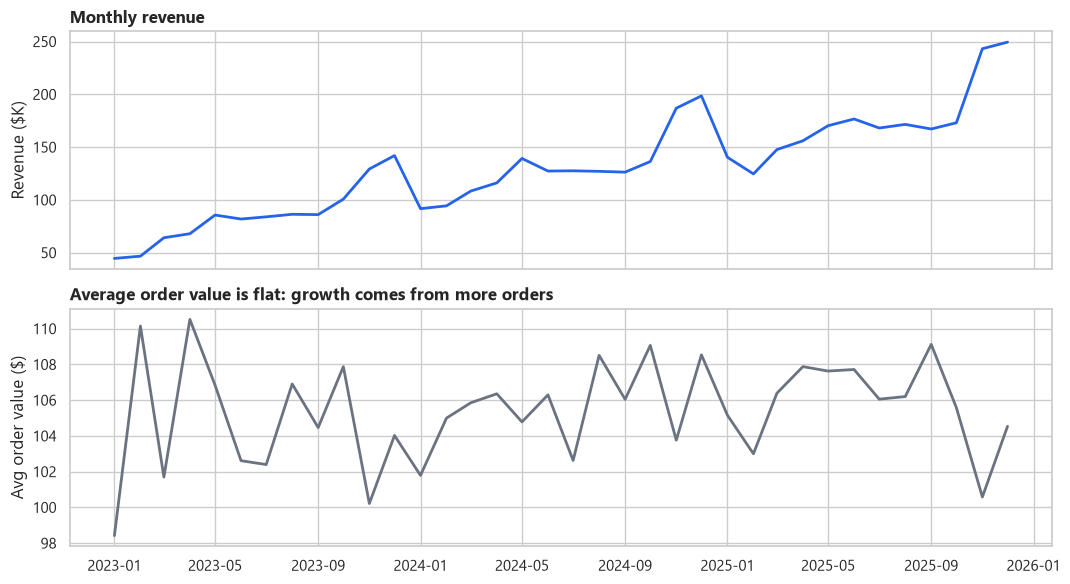

In [3]:
valid = orders[orders.order_status != "canceled"]
monthly = valid.set_index("order_purchase_timestamp").resample("MS").agg(
    revenue=("order_total", "sum"), orders=("order_id", "count"))
monthly["aov"] = monthly.revenue / monthly.orders

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(monthly.index, monthly.revenue / 1e3, color="#2563EB", lw=2)
ax[0].set_ylabel("Revenue ($K)"); ax[0].set_title("Monthly revenue", loc="left", fontweight="bold")
ax[1].plot(monthly.index, monthly.aov, color="#6B7280", lw=2)
ax[1].set_ylabel("Avg order value ($)"); ax[1].set_title("Average order value is flat: growth comes from more orders", loc="left", fontweight="bold")
plt.tight_layout()

In [4]:
yearly = valid.groupby(valid.order_purchase_timestamp.dt.year).agg(
    revenue=("order_total", "sum"), orders=("order_id", "count"), customers=("customer_id", "nunique"))
yearly["growth_%"] = yearly.revenue.pct_change() * 100
yearly

,revenue,orders,customers,growth_%
order_purchase_timestamp,,,,
2023,"1,019,440.65",9764,7632,NaN
2024,"1,579,873.60",14928,10853,54.97
2025,"2,088,042.39",19776,14011,32.17


## 2. Repeat customers

Repeat rate: 25.4% of customers ordered more than once


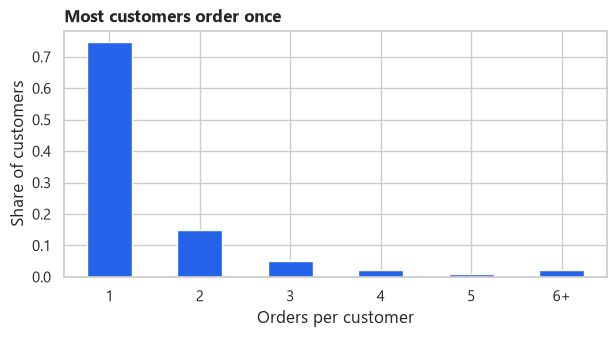

In [5]:
per_cust = valid.groupby("customer_id").size()
dist = per_cust.clip(upper=6).value_counts().sort_index()
dist.index = [str(i) if i < 6 else "6+" for i in dist.index]
print(f"Repeat rate: {(per_cust > 1).mean():.1%} of customers ordered more than once")
ax = (dist / dist.sum()).plot.bar(color="#2563EB", figsize=(7, 3.2), rot=0)
ax.set_xlabel("Orders per customer"); ax.set_ylabel("Share of customers")
ax.set_title("Most customers order once", loc="left", fontweight="bold");

## 3. Late deliveries, reviews and repeat purchase

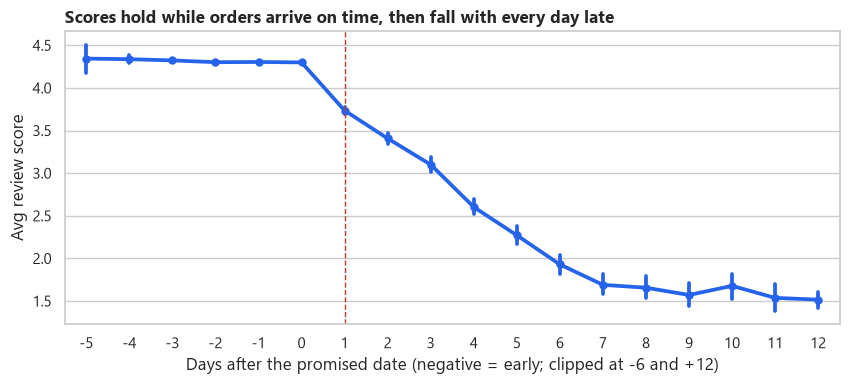

In [6]:
rev = q("""SELECT o.delay_days, o.carrier, r.review_score
           FROM orders o JOIN reviews r USING (order_id) WHERE o.order_status = 'delivered'""")
rev["delay"] = rev.delay_days.clip(-6, 12).astype(int)
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.pointplot(data=rev, x="delay", y="review_score", color="#2563EB", errorbar=("ci", 95), ax=ax, markersize=4)
ax.axvline(6, color="#C0392B", ls="--", lw=1)   # x position of delay = 0
ax.set_xlabel("Days after the promised date (negative = early; clipped at -6 and +12)")
ax.set_ylabel("Avg review score")
ax.set_title("Scores hold while orders arrive on time, then fall with every day late", loc="left", fontweight="bold");

In [7]:
first = q("""WITH ranked AS (
    SELECT o.*, ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY order_purchase_timestamp) AS n,
           COUNT(*) OVER (PARTITION BY customer_id) AS total_orders
    FROM orders o WHERE order_status <> 'canceled')
SELECT delay_days, total_orders > 1 AS came_back, carrier FROM ranked
WHERE n = 1 AND order_status = 'delivered' AND order_purchase_timestamp < '2025-07-01'""")
first["first_delivery"] = pd.cut(first.delay_days, [-99, 0, 3, 99], labels=["On time", "1-3 days late", "4+ days late"])
first.groupby("first_delivery", observed=True).came_back.agg(["count", "mean"]).rename(
    columns={"count": "customers", "mean": "ordered_again"})

,customers,ordered_again
first_delivery,,
On time,19287,0.31
1-3 days late,2129,0.23
4+ days late,948,0.07


Customers whose **first** order arrived 4+ days late placed a second order far less often. Only first orders before July 2025 are counted, so every customer had at least six months to come back.

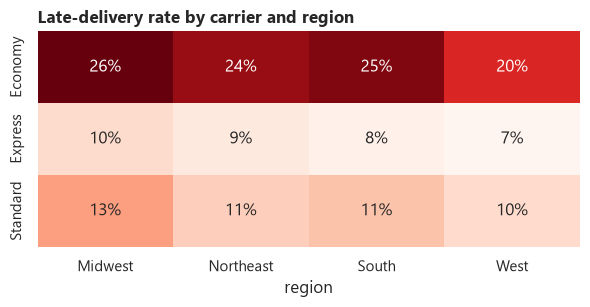

In [8]:
late = q("""SELECT o.carrier, c.region, AVG(o.is_late) AS late_rate
            FROM orders o JOIN customers c USING (customer_id)
            WHERE o.order_status = 'delivered' GROUP BY 1, 2""").pivot(index="carrier", columns="region", values="late_rate")
fig, ax = plt.subplots(figsize=(7, 2.8))
sns.heatmap(late, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=ax)
ax.set_title("Late-delivery rate by carrier and region", loc="left", fontweight="bold"); ax.set_ylabel("");

## 4. RFM segments
R and M are quintiles; F uses order-count bands (see `sql/analysis.sql`, query 05).

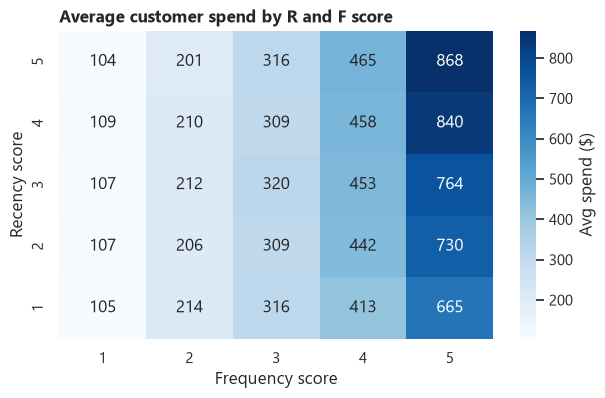

In [9]:
heat = rfm.pivot_table(index="r_score", columns="f_score", values="monetary", aggfunc="mean").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Avg spend ($)"}, ax=ax)
ax.set_xlabel("Frequency score"); ax.set_ylabel("Recency score")
ax.set_title("Average customer spend by R and F score", loc="left", fontweight="bold");

In [10]:
seg = rfm.groupby("segment").agg(customers=("customer_id", "count"), revenue=("monetary", "sum"),
                                 avg_recency=("recency_days", "mean"), avg_orders=("frequency", "mean"))
seg["pct_customers"] = seg.customers / seg.customers.sum() * 100
seg["pct_revenue"] = seg.revenue / seg.revenue.sum() * 100
seg.sort_values("revenue", ascending=False)

,customers,revenue,avg_recency,avg_orders,pct_customers,pct_revenue
segment,,,,,,
New Customers,8303,"882,717.17",112.88,1.00,28.18,18.83
Hibernating,5371,"676,879.78",611.44,1.19,18.23,14.44
Lost,5681,"674,309.49",897.12,1.13,19.28,14.39
Champions,1031,"673,159.95",97.03,6.20,3.50,14.36
Need Attention,5298,"661,557.52",379.61,1.17,17.98,14.11
Loyal,1306,"482,871.72",228.47,3.54,4.43,10.30
Potential Loyalists,1738,"358,203.25",118.69,2.00,5.90,7.64
At Risk,731,"277,657.76",673.57,3.65,2.48,5.92


## Takeaways
* Revenue grew 55% in 2024 and 32% in 2025 with a flat average order value: growth is from more customers and orders.
* About a quarter of customers order again; 60% of second orders come within 90 days of the first.
* Lateness is the biggest driver of bad reviews, and a first order that is 4+ days late cuts the chance of a second order to about a quarter of the on-time rate.
* Economy shipping and Midwest addresses have the highest late rates.
* Champions and Loyal customers (8% of customers) bring in a quarter of revenue; At Risk customers are the most valuable group to win back.